# Test singularity tracing in sum-of-products KEO of acetylene ($\mathrm{C_2H_2}$) using valence coordinates

The torsional coordinate $\tau$ in $\mathrm{C_2H_2}$ (and similarly, e.g., in $\mathrm{H_2O_2}$) becomes undefined when at least one of the valence angles $\angle\mathrm{H_iCC}$ approaches $180^\circ$.
At this geometry, the corresponding element of the KEO $G$-matrix, $G_{\tau\tau}$, becomes singular.

Here, we test the capability of `keosop` to accurately identify and represent the singular terms associated with the torsional coordinate $\tau$.
We compute $G_{\tau\tau}$ in sum-of-products form and validate it against an analytical expression provided by Sergei Yurchenko (ExoMol/UCL).
The two representations are evaluated and compared on a grid along the torsional coordinate $\tau$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import constants

from keosop.sing.gmat import Gmat
from keosop.sing.zmat import cartesian_to_internal, internal_to_cartesian

sns.set_theme(style="ticks", context="paper", font_scale=1.5)
plt.rcParams["figure.dpi"] = 300
plt.rcParams.update({"text.usetex": True, "font.family": "serif", "font.size": 14})

# converts G-matrix to cm^-1 units
G_to_invcm = (
    constants.value("Planck constant")
    * constants.value("Avogadro constant")
    * 1e16
    / (4.0 * np.pi**2 * constants.value("speed of light in vacuum"))
    * 1e5
)

Define Z-matrix coordinates

In [2]:
masses = np.array([12.0, 12.0, 1.007825, 1.007825])  # C, C, H, H

zmat_connections = [
    (0, 0, 0, 0),
    (1, 0, 0, 0),
    (1, 2, 0, 0),
    (2, 1, 3, 0),
]

Define one-dimensional grids for the internal coordinate representation and construct the G-matrix and pseudopotential in sum-of-products form

In [3]:
rad = np.pi / 180.0

# define 1D gris, essentially only for tau coordinate
grids = [
    np.linspace(1.2, 1.2, 1),
    np.linspace(1.1, 1.1, 1),
    np.linspace(1.1, 1.1, 1),
    np.linspace(179.9 * rad, 179.99 * rad, 4),
    np.linspace(179.9 * rad, 179.99 * rad, 4),
    np.linspace(0 * rad, 360 * rad, 100),
]

ncoo = len(grids)

# compute G-matrix and pseudopotential
gmat = Gmat(
    grids,
    masses,
    lambda q: internal_to_cartesian(zmat_connections, q),
    lambda xyz: cartesian_to_internal(zmat_connections, xyz),
    trace_singularities=True,
    singularity_coo=(3, 4),
    singularity_kinds=("sin",),
)

gvib_sop, grovib_sop, grot_sop = gmat.run(return_rot=True)
pseudo_sop = gmat.build_pseudopotential_fdf()

print("Number of terms in Gvib_{i,j}\n i  j no.terms  sing. summary")
for i in range(ncoo):
    for j in range(i, ncoo):
        print(
            f"{i:2d} {j:2d} {gvib_sop[i, j].nterms:6d} {gvib_sop[i,j].singularity_summary()}"
        )

print("\nNumber of terms in Grovib_{i,j}\n i  j no.terms  sing. summary")
for i in range(3):
    for j in range(ncoo):
        print(
            f"{i:2d} {j:2d} {grovib_sop[i, j].nterms:6d} {gvib_sop[i,j].singularity_summary()}"
        )

print("\nNumber of terms in Grot_{i,j}\n i  j no.terms  sing. summary")
for i in range(3):
    for j in range(i, 3):
        print(
            f"{i:2d} {j:2d} {grot_sop[i, j].nterms:6d} {grot_sop[i,j].singularity_summary()}"
        )

print("\nNumber of terms in pseudopotential\n no.terms  sing. summary")
print(f"{pseudo_sop.nterms:6d}    {pseudo_sop.singularity_summary()}")

Number of terms in Gvib_{i,j}
 i  j no.terms  sing. summary
 0  0      1 {(): 1}
 0  1      1 {(): 1}
 0  2      1 {(): 1}
 0  3      1 {((3, 'sin', -1.0),): 1}
 0  4      1 {((4, 'sin', -1.0),): 1}
 0  5      1 {(): 1}
 1  1      1 {(): 1}
 1  2      1 {(): 1}
 1  3      1 {(): 1}
 1  4      1 {(): 1}
 1  5      1 {((4, 'sin', -1.0),): 1}
 2  2      1 {(): 1}
 2  3      1 {((3, 'sin', -1.0),): 1}
 2  4      1 {((4, 'sin', -1.0),): 1}
 2  5      1 {((3, 'sin', -1.0),): 1}
 3  3      1 {((3, 'sin', -2.0),): 1}
 3  4      3 {(): 1, ((3, 'sin', -1.0),): 1, ((4, 'sin', -1.0),): 1}
 3  5      2 {((4, 'sin', -1.0),): 1, ((3, 'sin', -1.0), (4, 'sin', -1.0)): 1}
 4  4      1 {((4, 'sin', -2.0),): 1}
 4  5      2 {((3, 'sin', -1.0),): 1, ((3, 'sin', -1.0), (4, 'sin', -1.0)): 1}
 5  5      4 {((4, 'sin', -2.0),): 1, ((3, 'sin', -1.0), (4, 'sin', -1.0)): 2, ((3, 'sin', -2.0),): 1}

Number of terms in Grovib_{i,j}
 i  j no.terms  sing. summary
 0  0      1 {(): 1}
 0  1      1 {(): 1}
 0  2      1

As can be seen from the output of the previous cell, $G_{\tau\tau}$ (`gvib_sop[5, 5]`) contains one term proportional to $A\sin^{-2}(q_4)$, two terms proportional to $B\sin^{-1}(q_3)\sin^{-1}(q_4)$, and one term proportional to $C\sin^{-2}(q_3)$.

Below, we compare the corresponding regularized quantity

$$
\tilde{G}_{\tau\tau}=A+B+C,
$$

with its exact analytical expression by evaluating both representations on a grid along the dihedral coordinate $\tau$.

In [4]:
# evaluate one SOP term
def eval_sop_term(sop, iterm, inds, grids):

    # regular numerical SOP part
    value = 1.0
    for k in range(sop.ncoo):
        value *= sop.terms[iterm][k][inds[k]]

    # analytical singular part
    for k, kind, power in sop.singularities[iterm]:
        q = grids[k][inds[k]]

        if kind == "q":
            base = q
        elif kind == "sin": # skip the evaluation of 1/sin(angle) singular prefactor
            # base = np.sin(q)
            continue
        elif kind == "cos":
            base = np.cos(q)
        else:
            raise ValueError(f"Unknown singularity kind: {kind}")

        value *= base**power

    return value


# evaluate a complete SumProd object at one direct-product grid point
def eval_sop(sop, inds, grids):
    return sum(
        eval_sop_term(sop, iterm, inds, grids)
        for iterm in range(sop.nterms)
    )

In [5]:
# generate grid for tau-coordinate (icoo=5),
# taking the mid-point for other coordinates
icoo = 5

midpoints = np.array([g[len(g) // 2] for g in grids])
grid = np.tile(midpoints, (len(grids[icoo]), 1))
grid[:, icoo] = grids[icoo]

# indices mapping to the 1D grids
mid_indices = np.array([len(g) // 2 for g in grids])
grid_indices = np.tile(mid_indices, (len(grids[icoo]), 1))
grid_indices[:, icoo] = np.arange(len(grids[icoo]))

# number of multidimensional grid points
npoints = grid.shape[0]

gvib_sop_eval = np.zeros((npoints, ncoo, ncoo), dtype=np.float64)
grot_sop_eval = np.zeros((npoints, 3, 3), dtype=np.float64)
grovib_sop_eval = np.zeros((npoints, 3, ncoo), dtype=np.float64)
pseudo_sop_eval = np.zeros((npoints,), dtype=np.float64)

# Gvib
for ipoint, inds in enumerate(grid_indices):
    for i in range(ncoo):
        for j in range(ncoo):
            gvib_sop_eval[ipoint, i, j] = (
                eval_sop(gvib_sop[i, j], inds, grids) * G_to_invcm
            )

# Grot
for ipoint, inds in enumerate(grid_indices):
    for i in range(3):
        for j in range(3):
            grot_sop_eval[ipoint, i, j] = (
                eval_sop(grot_sop[i, j], inds, grids) * G_to_invcm
            )

# Grovib
for ipoint, inds in enumerate(grid_indices):
    for i in range(3):
        for j in range(ncoo):
            grovib_sop_eval[ipoint, i, j] = (
                eval_sop(grovib_sop[i, j], inds, grids) * G_to_invcm
            )

# pseudopotential
for ipoint, inds in enumerate(grid_indices):
    pseudo_sop_eval[ipoint] = eval_sop(pseudo_sop, inds, grids) * G_to_invcm

Compute $\tilde{G}_{\tau\tau}$ using analytical expression

In [6]:
def Gtau_analytic_nonsingular(q):
    CC, CH1, CH2, alpha1, alpha2, tau = q

    theta_1 = np.pi - alpha1
    theta_2 = np.pi - alpha2

    mC = masses[0]
    mH = masses[2]

    st1 = np.sin(theta_1)
    st2 = np.sin(theta_2)
    ct1 = np.cos(theta_1)
    ct2 = np.cos(theta_2)

    # 1 / sin(theta_1)^2 group
    fac1 = (
        1.0 / (CH1**2 * mH)
        + 1.0 / (CH1**2 * mC)
        + 2.0 * ct1 / (CH1 * CC * mC)
        + 2.0 * ct1**2 / (CC**2 * mC)
    ) * G_to_invcm

    # 1 / sin(theta_2)^2 group
    fac2 = (
        1.0 / (CH2**2 * mH)
        + 2.0 * ct2 / (CC * CH2 * mC)
        + 1.0 / (CH2**2 * mC)
        + 2.0 * ct2**2 / (CC**2 * mC)
    ) * G_to_invcm

    # 1 / (sin(theta_1) * sin(theta_2)) group
    fac12 = (
        (
            2.0 * ct2 / (CH1 * CC * mC)
            + 2.0 * ct1 / (CC * CH2 * mC)
            + 4.0 * ct1 * ct2 / (CC**2 * mC)
        )
        * np.cos(tau)
        * G_to_invcm
    )

    return fac1, fac2, fac12


gtau_analytic_eval = []

for x in grid:
    f1, f2, f12 = Gtau_analytic_nonsingular(x)
    gtau_analytic_eval.append(f1 + f2 + f12)

gtau_analytic_eval = np.array(gtau_analytic_eval)

Plot sum-of-products and analytical results

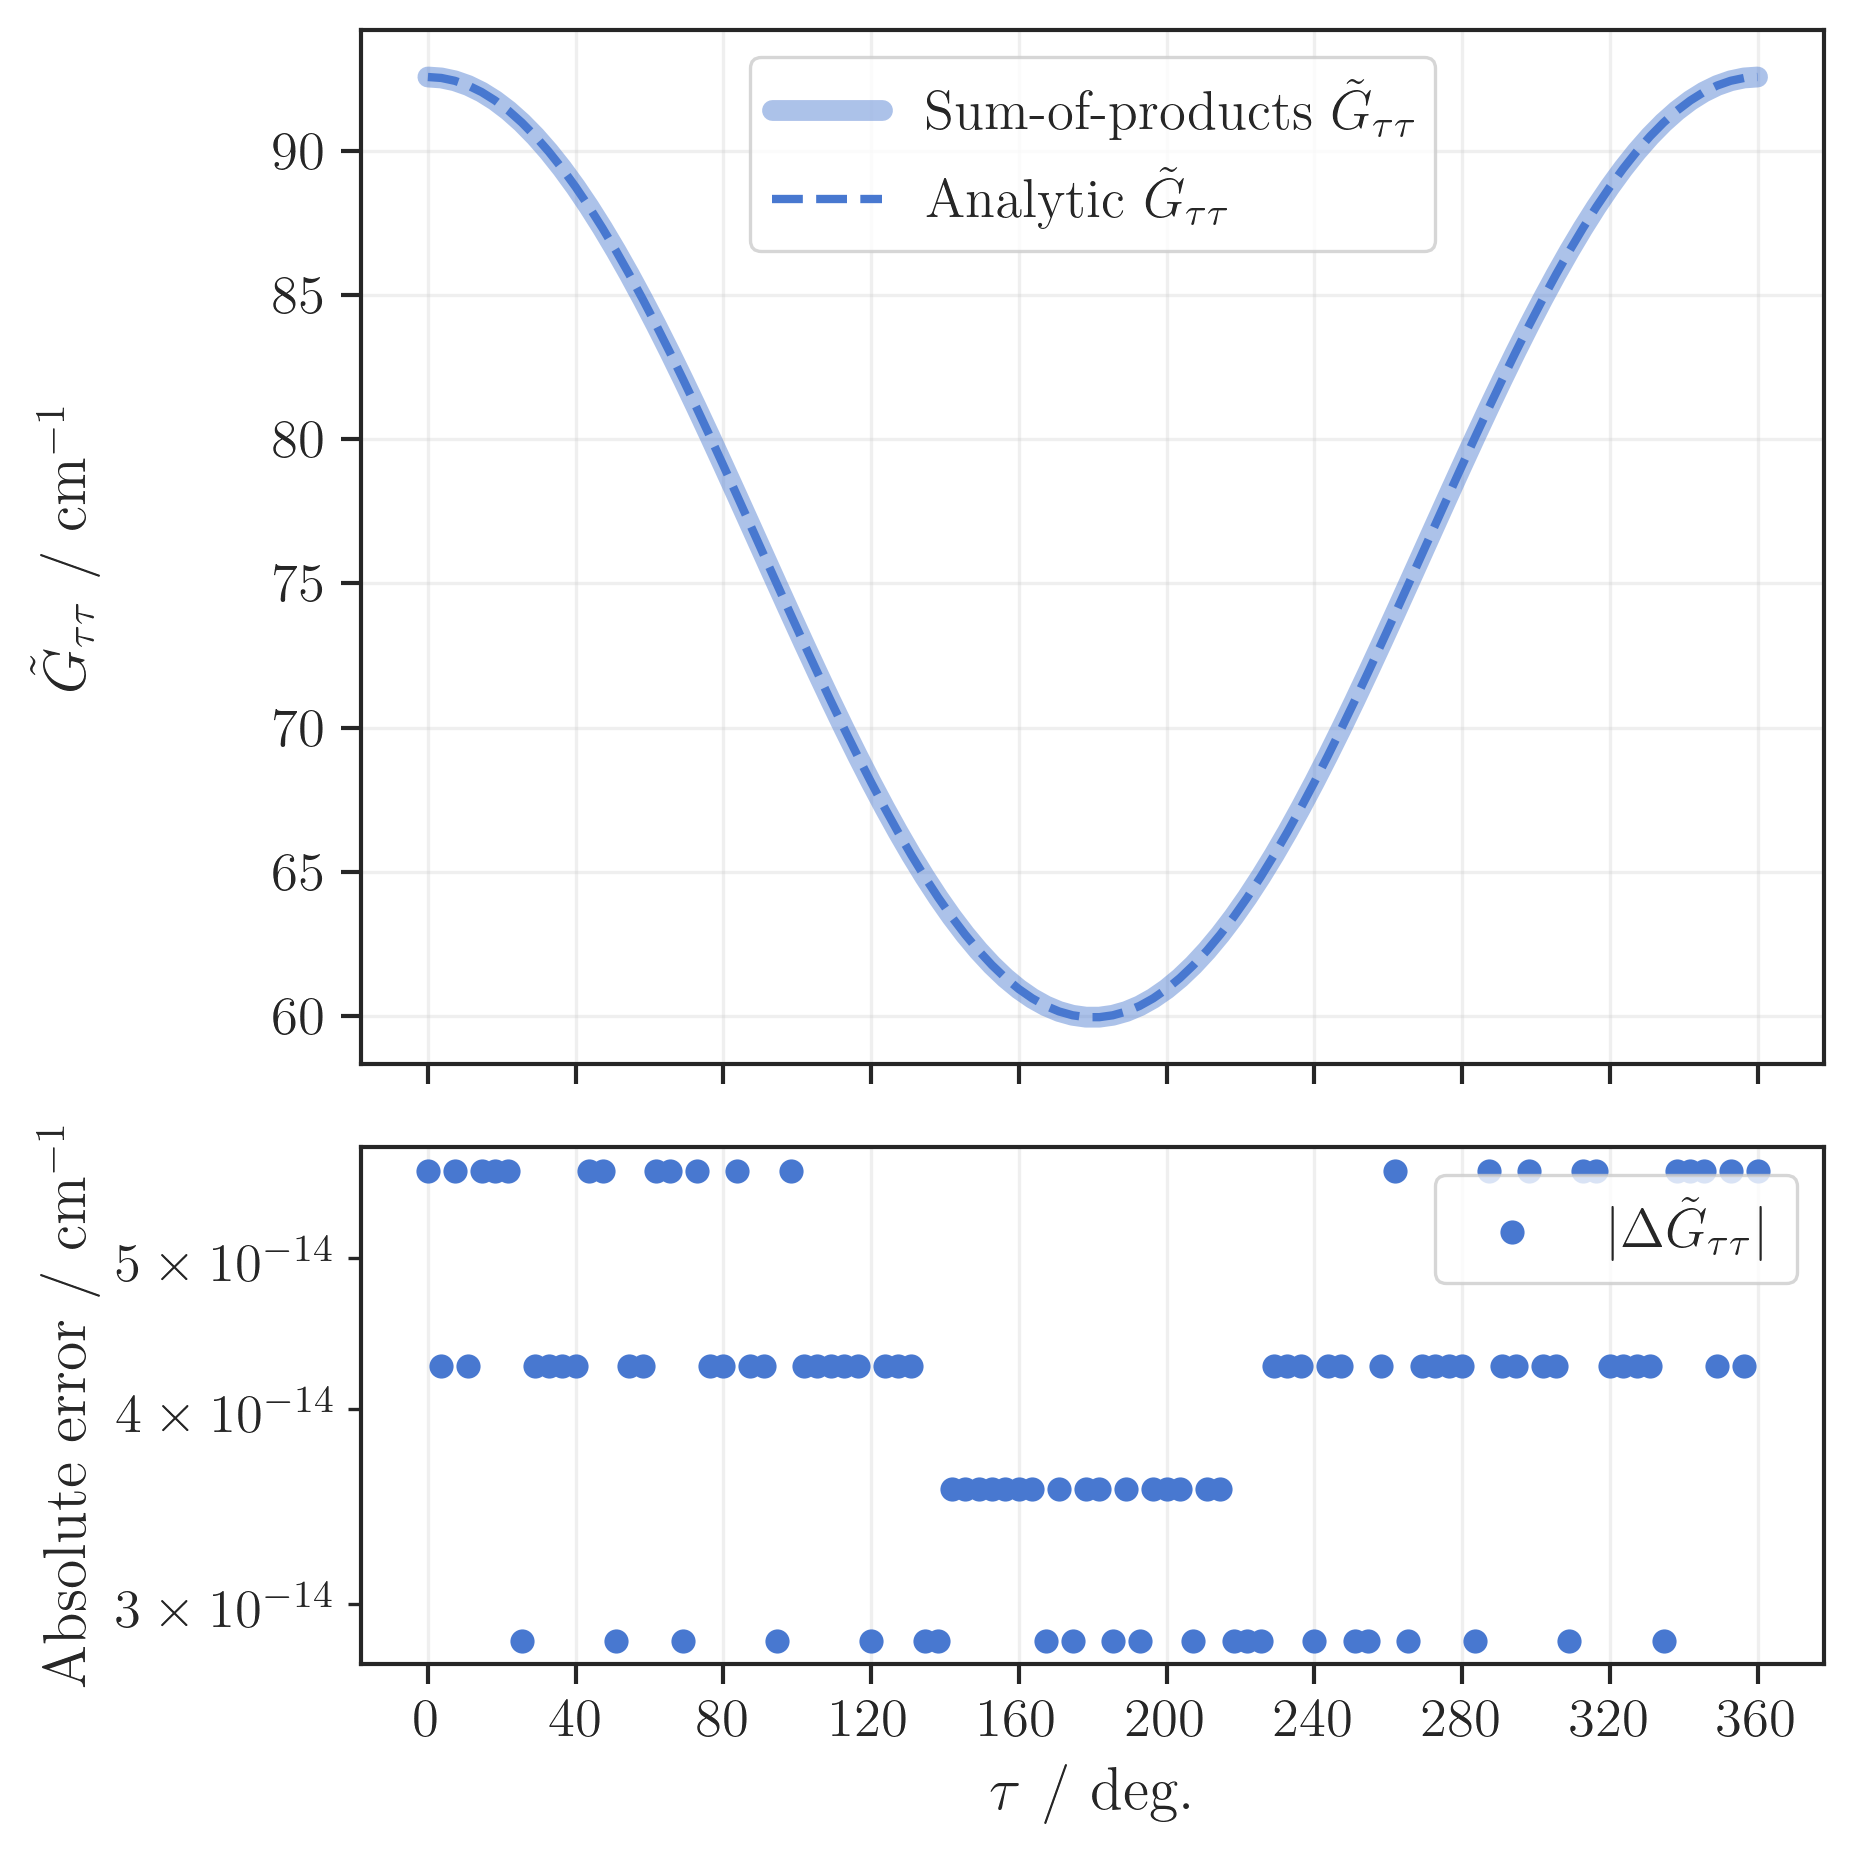

In [7]:
tau = grid[:, -1] * 180 / np.pi

colors = sns.color_palette("muted", n_colors=3)

scale = 0.8
fig, (ax1, ax2) = plt.subplots(
    2,
    1,
    figsize=(8 * scale, 8 * scale),
    sharex=True,
    gridspec_kw={"height_ratios": [2, 1]},
)

curves = [
    (gvib_sop_eval[:, 5, 5], gtau_analytic_eval, r"$\tilde{G}_{\tau\tau}$", colors[0]),
]

for sop, analytic, label, color in curves:
    ax1.plot(
        tau,
        sop,
        color=color,
        linewidth=5,
        alpha=0.45,
        label=rf"Sum-of-products {label}",
    )

    ax1.plot(
        tau,
        analytic,
        color=color,
        linewidth=2,
        linestyle="--",
        label=rf"Analytic {label}",
    )

ax1.set_ylabel(r"$\tilde{G}_{\tau\tau}$ / $\mathrm{cm^{-1}}$")
ax1.legend(ncol=1)
ax1.grid(True, alpha=0.3)

errors = [
    (
        np.abs(gvib_sop_eval[:, 5, 5] - gtau_analytic_eval),
        r"$|\Delta\tilde{G}_{\tau\tau}|$",
        colors[0],
    ),
]

for error, label, color in errors:
    ax2.scatter(tau, error, color=color, label=label, s=25)

ax2.set_yscale("log")
ax2.set_xticks(np.arange(0, 361, 40))
ax2.set_xlabel(r"$\tau$ / deg.")
ax2.set_ylabel(r"Absolute error / $\mathrm{cm^{-1}}$")
ax2.legend(ncol=1)
ax2.grid(True, alpha=0.3)

fig.align_ylabels()
fig.tight_layout()

fig.savefig("hcch_sing.pdf", bbox_inches="tight", dpi=300)
plt.show()